# Urban Land Cover Analysis Pipeline -- Phase 2 Progress Report

**Group H:** Nisarg Shah, Ansar Rahman

Digital Image Processing -- Course Project, Phase 2 (progress checkpoint), October 2026

Repository: https://github.com/nisarg-007/dip-urban-land-cover-pipeline

## 1. Project Objective

We are building a classical (non-machine-learning) image-processing pipeline that makes an urban aerial scene easier
to interpret for land-cover discrimination, so that roads, buildings, vegetation and water can be told apart and
measured. The pipeline corrects illumination and contrast so that shadowed regions are usable, enhances local
contrast, denoises and sharpens structural detail, separates coarse regions from fine detail in the frequency domain,
and extracts edges and corners (building outlines, road intersections) that a later segmentation step can build on.

In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 9})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)
# Tables render as real LaTeX tables in the PDF export
pd.set_option("styler.render.repr", "latex")
pd.set_option("styler.format.precision", 3)
pd.set_option("styler.latex.hrules", True)
pd.set_option("styler.format.escape", "latex")

DATA_PATH = os.path.join("data", "naip_raw.png")
color = cv2.imread(DATA_PATH, cv2.IMREAD_COLOR)
assert color is not None, f"could not read {DATA_PATH}"
gray = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)

# Zoom window used for close-up comparisons (tall-building shadows, I-45 ramps, parking lots)
CROP = (slice(380, 764), slice(300, 684))

# Tone bands used by several metrics below
shadow_mask = gray <= np.percentile(gray, 25)
bright_mask = gray >= np.percentile(gray, 75)


def rgb(im):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im


def show(images, titles, suptitle=None, cols=None, size=3.4, crop=False):
    cols = cols or len(images)
    rows = int(np.ceil(len(images) / cols))
    height = (size + 0.55) * rows + 0.4
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, height), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, im, t in zip(axes.ravel(), images, titles):
        im = im[CROP] if crop else im
        ax.imshow(rgb(im), cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255)
        ax.set_title(t)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.35 / height))
    plt.show()


def local_std_map(img, k=16):
    f = img.astype(np.float32)
    m = cv2.blur(f, (k, k))
    return np.sqrt(np.clip(cv2.blur(f * f, (k, k)) - m * m, 0, None))


def psnr(ref, img):
    mse = np.mean((ref.astype(np.float64) - img.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


print("image size:", gray.shape[::-1], "| gray min/mean/max:", gray.min(), round(gray.mean(), 1), gray.max())

image size: (1024, 1024) | gray min/mean/max: 45 161.6 253


## 2. Dataset / Image Sample

**Source:** USDA **NAIP** (National Agriculture Imagery Program) 1 m/pixel true-color aerial orthoimagery, retrieved
from the USGS National Map NAIP ImageServer (the same NAIP holdings indexed by USGS EarthExplorer). NAIP is U.S.
Government public-domain data (credit: USDA Farm Production and Conservation Business Center / USGS).

**Scene:** a 1024 x 1024 px crop of downtown Houston, TX, at the I-45 (Pierce Elevated) / US-59 interchange, near the
George R. Brown Convention Center and Discovery Green. One frame contains high-rise buildings with long shadows, a
multi-level highway interchange, a street grid, parking lots, trees and lawns. Export request used:

`https://imagery.nationalmap.gov/arcgis/rest/services/USGSNAIPImagery/ImageServer/exportImage?bbox=-95.377495,29.748295,-95.366905,29.757515&bboxSR=4326&imageSR=4326&size=1024,1024&format=png&f=image`

The image is saved in the repository as `data/naip_raw.png`. Because a 1024 px frame is small in print, most
parameter comparisons below are also shown on a 384 x 384 px zoom window (yellow box), which covers building shadows,
the highway ramps and parking lots.

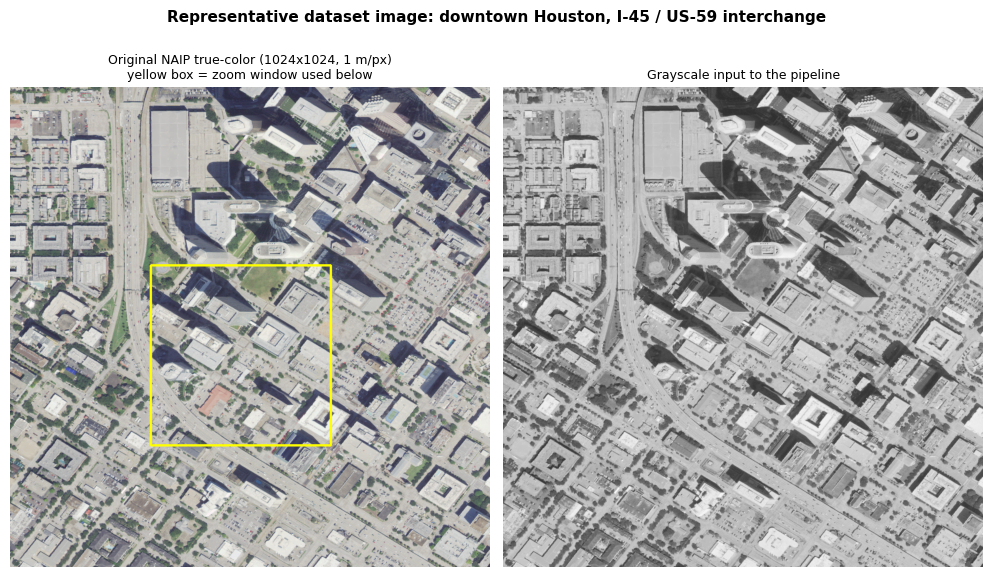

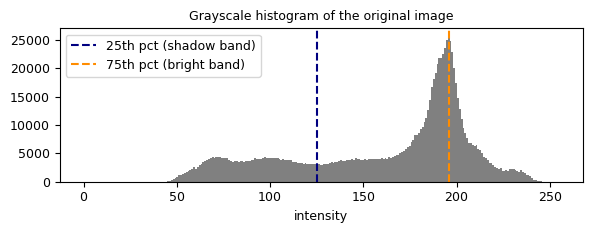

In [3]:
boxed = color.copy()
cv2.rectangle(boxed, (CROP[1].start, CROP[0].start), (CROP[1].stop, CROP[0].stop), (0, 255, 255), 4)
show([boxed, gray], ["Original NAIP true-color (1024x1024, 1 m/px)\nyellow box = zoom window used below",
                     "Grayscale input to the pipeline"],
     suptitle="Representative dataset image: downtown Houston, I-45 / US-59 interchange", size=5)

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.hist(gray.ravel(), bins=256, range=(0, 255), color="gray")
ax.axvline(np.percentile(gray, 25), color="navy", ls="--", label="25th pct (shadow band)")
ax.axvline(np.percentile(gray, 75), color="darkorange", ls="--", label="75th pct (bright band)")
ax.set_title("Grayscale histogram of the original image"); ax.set_xlabel("intensity"); ax.legend()
fig.tight_layout(); plt.show()

## 3. Implemented Processing Stages

We implemented techniques from all five project categories: point processing, histogram processing, spatial
filtering, frequency-domain filtering, and edge & corner detection. Each stage shows the input, the output, a
parameter experiment, and a short analysis.

### 3.1 Point Processing -- Gamma Correction and Linear Contrast Stretch

**Gamma correction** uses $s = 255\,(r/255)^{1/\gamma}$, so $\gamma > 1$ brightens. Instead of picking $\gamma$ by eye, we
define "shadow" pixels as the darkest 25% of the scene and solve for the $\gamma$ that moves their mean to a mid-gray
target of 110: $\gamma = \ln(\bar r_{shadow}/255) / \ln(110/255)$. We compare it against no correction and two stronger values.

The local-contrast gain columns divide the mean local standard deviation (16 x 16 window) after correction by the
value before correction, separately for the darkest and brightest quartiles. A value below 1 means texture in that
band was flattened.

In [4]:
def gamma_correct(img, g):
    return np.clip(255.0 * np.power(img / 255.0, 1.0 / g), 0, 255).astype(np.uint8)

shadow_mean = float(gray[shadow_mask].mean())
TARGET = 110.0
gamma_auto = float(np.log(shadow_mean / 255.0) / np.log(TARGET / 255.0))

base_std = local_std_map(gray)
rows, gamma_imgs = [], {}
for g in [1.0, gamma_auto, 1.6, 2.2]:
    out = gamma_correct(gray, g)
    s = local_std_map(out)
    gamma_imgs[g] = out
    rows.append({"gamma": g,
                 "shadow mean": out[shadow_mask].mean(),
                 "bright mean": out[bright_mask].mean(),
                 "shadow local-contrast gain": s[shadow_mask].mean() / base_std[shadow_mask].mean(),
                 "bright local-contrast gain": s[bright_mask].mean() / base_std[bright_mask].mean()})
gamma_table = pd.DataFrame(rows)
print(f"shadow-quartile mean before correction = {shadow_mean:.1f}; solved gamma = {gamma_auto:.3f}")
gamma_table

shadow-quartile mean before correction = 89.5; solved gamma = 1.245


,gamma,shadow mean,bright mean,shadow local-contrast gain,bright local-contrast gain
0,1.000,89.495,207.126,1.000,1.000
1,1.245,109.106,215.269,0.919,0.884
2,1.600,131.221,223.416,0.811,0.753
3,2.200,156.918,231.323,0.667,0.596


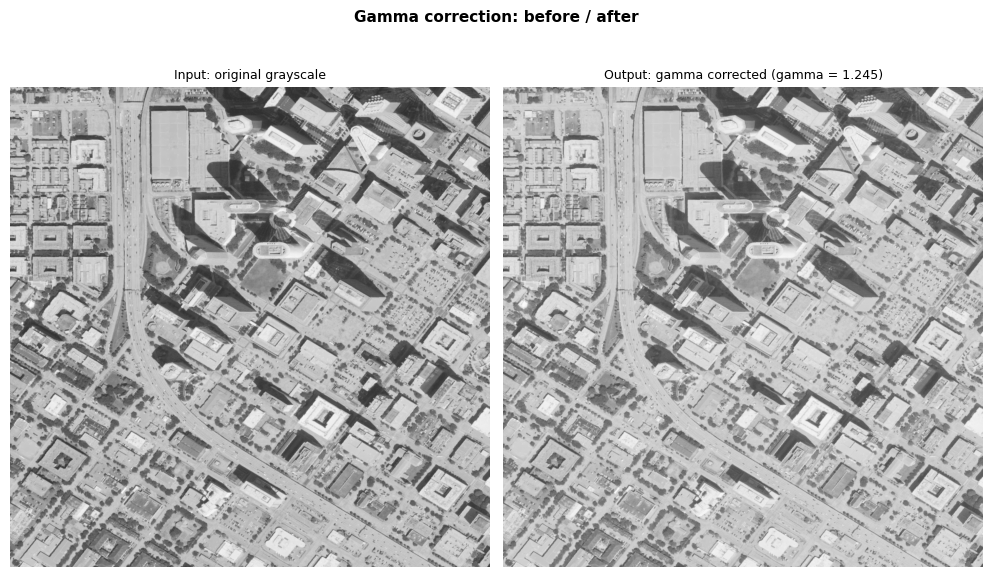

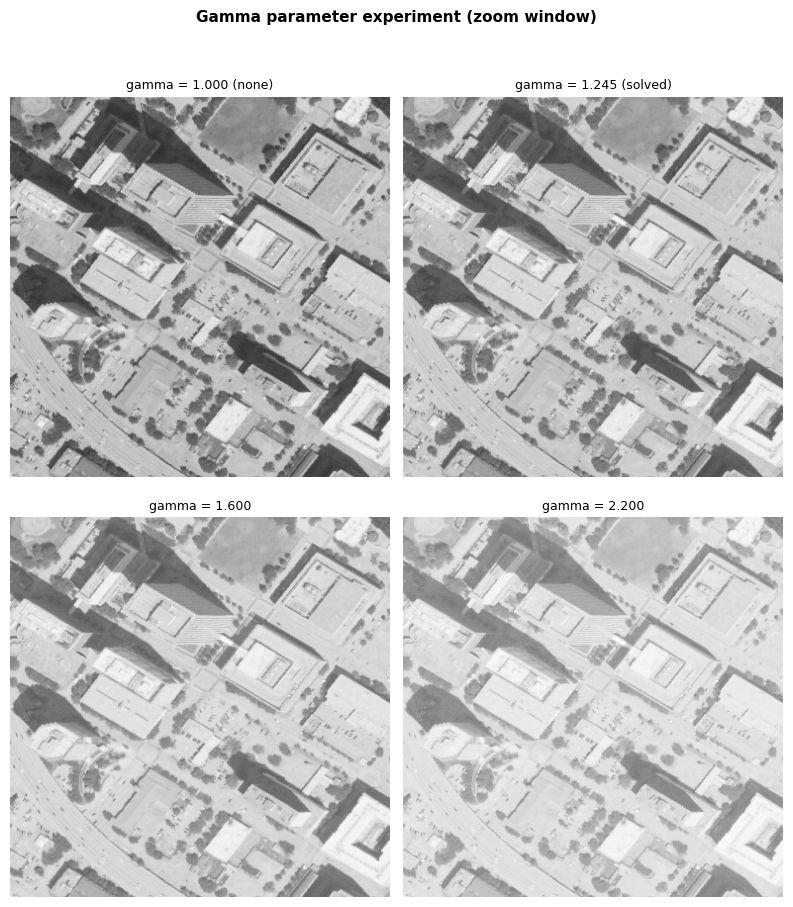

In [5]:
gamma_img = gamma_imgs[gamma_auto]
show([gray, gamma_img], ["Input: original grayscale", f"Output: gamma corrected (gamma = {gamma_auto:.3f})"],
     suptitle="Gamma correction: before / after", size=5)
show([gamma_imgs[g] for g in gamma_imgs],
     [f"gamma = {g:.3f}" + (" (none)" if g == 1.0 else " (solved)" if g == gamma_auto else "") for g in gamma_imgs],
     cols=2, size=4, suptitle="Gamma parameter experiment (zoom window)", crop=True)

**Parameter result.** The solved value $\gamma = 1.245$ moves the shadow mean from 89.5 to 109.1, within 1% of the
target of 110. $\gamma = 1.6$ and $2.2$ overshoot (131 and 157) and lighten the image visibly. They also flatten
texture: bright-band contrast gain drops to 0.75 and 0.60, so light roofs and pavement start to wash out. The solved
$\gamma$ worked best because it is the smallest correction that reaches the target, so it costs the least highlight
contrast.

**Analysis.**

- *What changed:* the whole image got brighter. The biggest change is in shadowed building faces and tree canopy,
  which move from near-black into the mid-tones.
- *Did it help:* partly. Shadowed areas are now in a usable intensity range, but gamma alone did **not** increase local
  contrast in the shadows (gain 0.92). It shifts brightness; it does not add detail. The stretch and CLAHE stages
  below supply the contrast.
- *Unwanted effects:* highlights are compressed (bright-band gain 0.88), so bright rooftops lose some texture.
- *Decision:* **keep**, using the solved $\gamma$ rather than a fixed value. Its main job is to move shadows into a
  range where the following contrast steps can work.

In [6]:
rows = [{"percentile clip": "none (input)", "input low": gamma_img.min(), "input high": gamma_img.max(),
         "% pixels saturated (0 or 255)": 100 * np.mean((gamma_img == 0) | (gamma_img == 255)),
         "global std": gamma_img.std(), "mean local std": local_std_map(gamma_img).mean()}]
stretch_imgs = {}
for lo, hi in [(0, 100), (2, 98), (5, 95)]:
    a, b = np.percentile(gamma_img, [lo, hi])
    out = np.clip((gamma_img.astype(np.float64) - a) * 255.0 / max(b - a, 1e-6), 0, 255).astype(np.uint8)
    stretch_imgs[(lo, hi)] = out
    rows.append({"percentile clip": f"{lo}/{hi}", "input low": a, "input high": b,
                 "% pixels saturated (0 or 255)": 100 * np.mean((out == 0) | (out == 255)),
                 "global std": out.std(),
                 "mean local std": local_std_map(out).mean()})
stretch_table = pd.DataFrame(rows)
stretched = stretch_imgs[(2, 98)]
stretch_table

,percentile clip,input low,input high,% pixels saturated (0 or 255),global std,mean local std
0,none (input),63.0,253.0,0.000,43.236,26.665
1,0/100,63.0,253.0,0.006,58.010,35.775
2,2/98,80.0,233.0,4.518,71.385,44.157
3,5/95,89.0,224.0,10.133,79.009,49.191


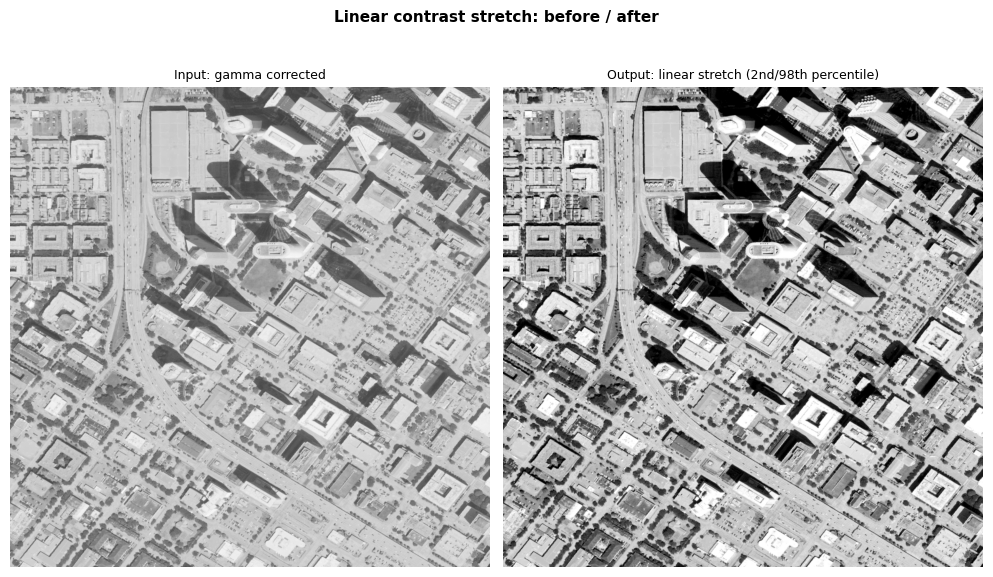

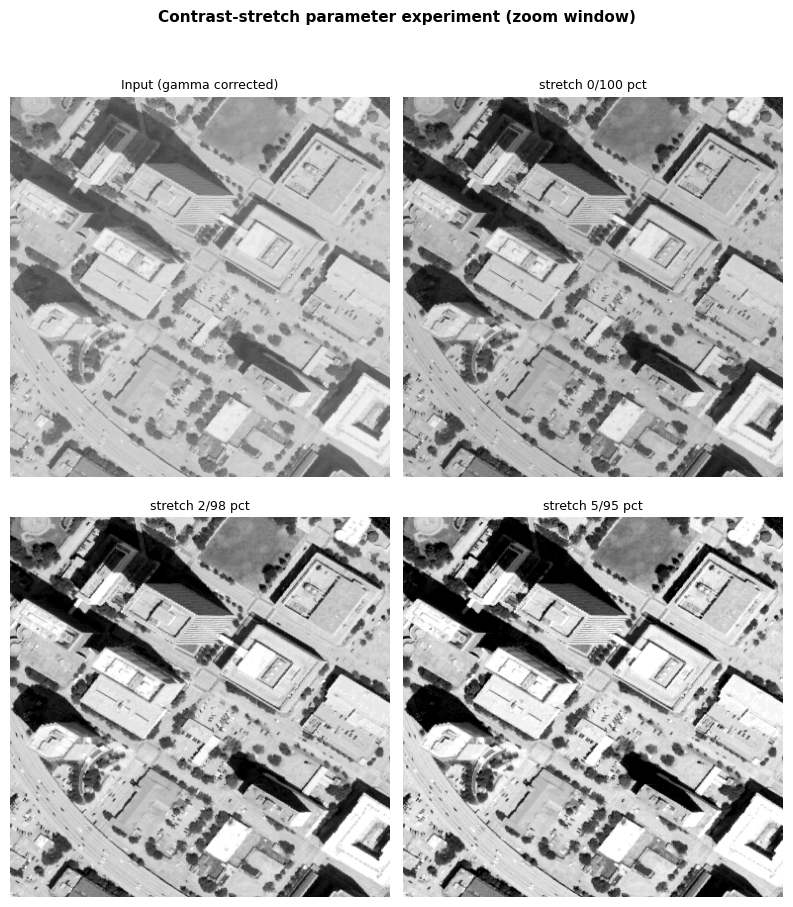

In [7]:
show([gamma_img, stretched], ["Input: gamma corrected", "Output: linear stretch (2nd/98th percentile)"],
     suptitle="Linear contrast stretch: before / after", size=5)
show([gamma_img] + list(stretch_imgs.values()),
     ["Input (gamma corrected)"] + [f"stretch {k[0]}/{k[1]} pct" for k in stretch_imgs],
     cols=2, size=4, suptitle="Contrast-stretch parameter experiment (zoom window)", crop=True)

**Parameter result.** We compared min/max stretching (0/100 percentile), a 2/98 percentile clip, and a 5/95 percentile
clip, starting from a mean local std of 26.7. Min/max raises it to 35.8 (+34%) but is limited by a few extreme pixels
at 63 and 253. The 2/98 clip ignores those outliers and raises local std to 44.2 (+66%) while saturating only 4.5% of
pixels. The 5/95 clip gives more contrast (49.2) but saturates 10% of the image, which turns the brightest roofs and
deepest shadows pure white and black. **2/98 worked best**: most of the gain, with a small, controlled amount of
clipping.

**Analysis.**

- *What changed:* the 80-233 intensity band that holds 96% of the pixels now covers the full 0-255 range, so pavement,
  roofs and lawns are spread further apart in tone.
- *Did it help:* yes. Global contrast (std 43.2 to 71.4) and local contrast (26.7 to 44.2) both increase.
- *Unwanted effects:* 4.5% of pixels are clipped, mostly specular roofs and the darkest shadow cores.
- *Decision:* **keep** with the 2/98 clip.

### 3.2 Histogram Processing -- CLAHE vs. Global Histogram Equalization

We vary the CLAHE clip limit (1.5, 2.5, 4.0) and tile grid (4 x 4, 8 x 8, 16 x 16), and compare against global
histogram equalization (HE). Three measures are reported, each relative to the stretched input:

- **gain dark / gain bright:** local-contrast gain in the darkest and brightest quartiles.
- **balance (dark/bright):** the ratio of those two gains. A value of 1.0 means both bands improved equally.
- **gain in flat regions:** local-contrast gain in the 20% smoothest neighborhoods (bare roofs and pavement). Gain
  there is mostly amplified noise and texture, so lower is better.

In [8]:
pre_std = local_std_map(stretched)
# "Flat" pixels = the 20% smoothest neighbourhoods (bare roofs, pavement). Contrast gain
# there is mostly amplified noise/texture, so it is tracked as an unwanted-effect metric.
flat_mask = pre_std <= np.percentile(pre_std, 20)

def he_metrics(name, out):
    s = local_std_map(out)
    gd = s[shadow_mask].mean() / pre_std[shadow_mask].mean()
    gb = s[bright_mask].mean() / pre_std[bright_mask].mean()
    return {"method": name, "mean local std": s.mean(), "gain dark": gd, "gain bright": gb,
            "balance (dark/bright)": gd / gb, "gain in flat regions": s[flat_mask].mean() / pre_std[flat_mask].mean()}

he_imgs = {"global HE": cv2.equalizeHist(stretched)}
for clip, tile in [(1.5, 8), (2.5, 8), (4.0, 8), (2.5, 4), (2.5, 16)]:
    he_imgs[f"CLAHE clip={clip}, tile={tile}"] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(stretched)
clahe_table = pd.DataFrame([he_metrics(k, v) for k, v in he_imgs.items()])
clahe_img = he_imgs["CLAHE clip=2.5, tile=8"]
clahe_table

,method,mean local std,gain dark,gain bright,balance (dark/bright),gain in flat regions
0,global HE,50.091,0.909,1.370,0.663,1.800
1,"CLAHE clip=1.5, tile=8",46.605,1.016,1.081,0.940,1.188
2,"CLAHE clip=2.5, tile=8",47.660,0.999,1.145,0.873,1.370
3,"CLAHE clip=4.0, tile=8",48.913,0.978,1.223,0.799,1.589
4,"CLAHE clip=2.5, tile=4",46.879,0.977,1.138,0.859,1.324
5,"CLAHE clip=2.5, tile=16",48.881,1.032,1.155,0.894,1.432


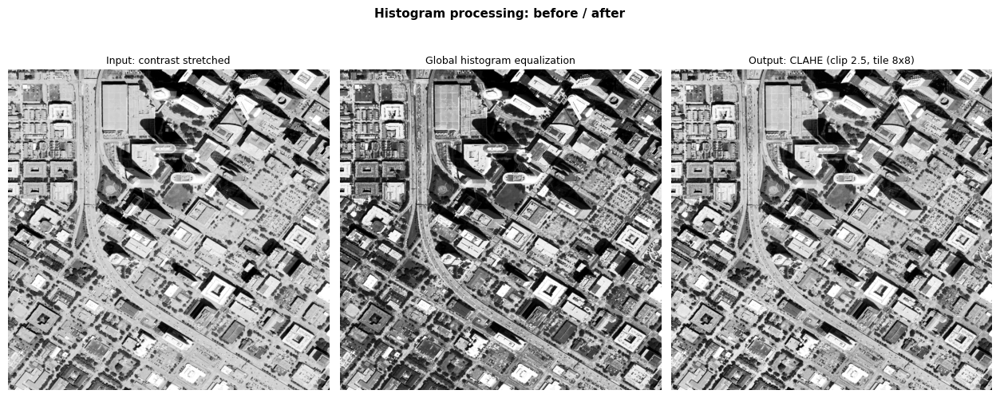

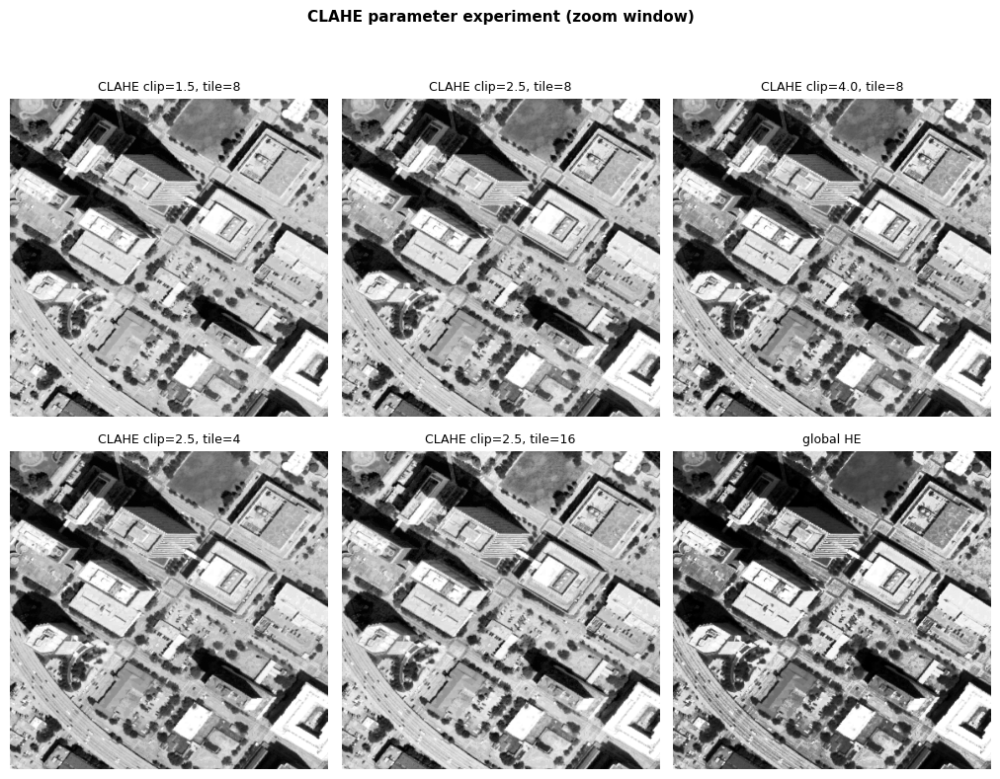

In [9]:
show([stretched, he_imgs["global HE"], clahe_img],
     ["Input: contrast stretched", "Global histogram equalization", "Output: CLAHE (clip 2.5, tile 8x8)"],
     suptitle="Histogram processing: before / after", size=4.2)
keys = ["CLAHE clip=1.5, tile=8", "CLAHE clip=2.5, tile=8", "CLAHE clip=4.0, tile=8",
        "CLAHE clip=2.5, tile=4", "CLAHE clip=2.5, tile=16", "global HE"]
show([he_imgs[k] for k in keys], keys, cols=3, suptitle="CLAHE parameter experiment (zoom window)", crop=True)

**Parameter result.** Global HE has the highest overall local contrast (50.1), but it is the most unbalanced method
(0.66). It *reduces* contrast in shadows (gain 0.91) while boosting bright areas by 1.37x, and it amplifies flat
regions the most (1.80x), which shows up as grainy roofs in the zoom window. All CLAHE settings are more balanced.
Raising the clip limit from 1.5 to 4.0 trades balance (0.94 down to 0.80) and noise (1.19x up to 1.59x) for a little
more contrast (46.6 up to 48.9). Tile size matters less: 4 x 4 gives slightly less contrast (46.9), and 16 x 16 gives
more contrast (48.9) but amplifies flat regions more (1.43x).

**Which setting worked better:** clip 1.5 had the best balance and the least noise amplification. Clip 2.5 (our
Phase 1 value) gives a bit more contrast, which helped Canny pick up low-contrast roof edges. For this checkpoint we
keep **clip 2.5, tile 8 x 8** because all downstream stages were tuned on it. We will re-run the downstream metrics
with clip 1.5 before Phase 3.

**Analysis.**

- *What changed:* texture inside shadows and on mid-gray pavement became visible, and building outlines stand out
  from their surroundings.
- *Did it help:* yes. CLAHE boosts both tone bands evenly, which is exactly what global HE fails to do on this mixed
  scene. This supports our Phase 1 reasoning with numbers.
- *Unwanted effects:* flat roofs and lots get grainier (1.37x local-contrast gain in flat regions).
- *Decision:* **keep**. We may lower the clip limit to 1.5 to 2.0 after testing it downstream.

### 3.3 Spatial Filtering -- Median Filtering and Laplacian Sharpening

**Median filtering.** The NAIP crop has almost no impulse noise, so to test the filter properly we add 2% synthetic
salt-and-pepper noise (fixed random seed) to the CLAHE output. We then compare median kernels k = 3, 5, 7 and a 3 x 3
mean filter against the clean image. We measure PSNR and the correlation between Laplacian edge maps (how much fine
edge structure survives). We also apply k = 3 to the *real, un-noised* image to see what the filter costs when no
noise is present.

In [10]:
rng = np.random.default_rng(0)
noisy = clahe_img.copy()
n = int(0.02 * noisy.size)
ys, xs = rng.integers(0, noisy.shape[0], n), rng.integers(0, noisy.shape[1], n)
noisy[ys[: n // 2], xs[: n // 2]] = 255
noisy[ys[n // 2:], xs[n // 2:]] = 0

lap_clean = cv2.Laplacian(clahe_img, cv2.CV_32F)
def edge_corr(img):
    return float(np.corrcoef(lap_clean.ravel(), cv2.Laplacian(img, cv2.CV_32F).ravel())[0, 1])

den_imgs = {"noisy input": noisy,
            "median k=3": cv2.medianBlur(noisy, 3),
            "median k=5": cv2.medianBlur(noisy, 5),
            "median k=7": cv2.medianBlur(noisy, 7),
            "mean (box) k=3": cv2.blur(noisy, (3, 3))}
median_table = pd.DataFrame([{"filter": k, "PSNR vs clean (dB)": psnr(clahe_img, v),
                              "edge correlation vs clean": edge_corr(v)} for k, v in den_imgs.items()])

# Cost of the median filter on the real (un-noised) image
med_real = cv2.medianBlur(clahe_img, 3)
print(f"median k=3 on the REAL clean image: PSNR vs unfiltered = {psnr(clahe_img, med_real):.1f} dB, "
      f"edge correlation = {edge_corr(med_real):.3f}")
median_table

median k=3 on the REAL clean image: PSNR vs unfiltered = 26.5 dB, edge correlation = 0.613


,filter,PSNR vs clean (dB),edge correlation vs clean
0,noisy input,21.768,0.505
1,median k=3,26.193,0.593
2,median k=5,22.235,0.381
3,median k=7,20.190,0.274
4,mean (box) k=3,23.804,0.358


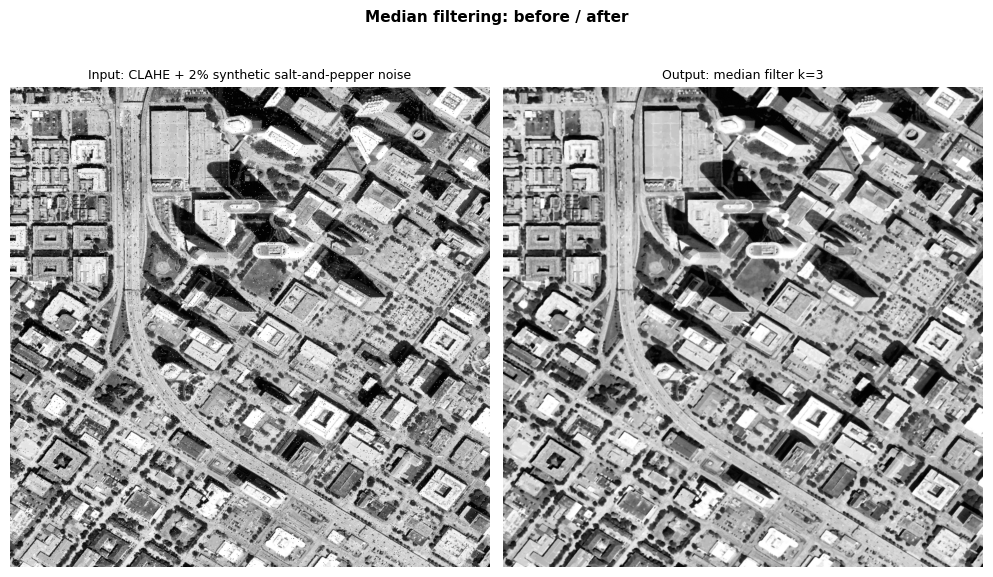

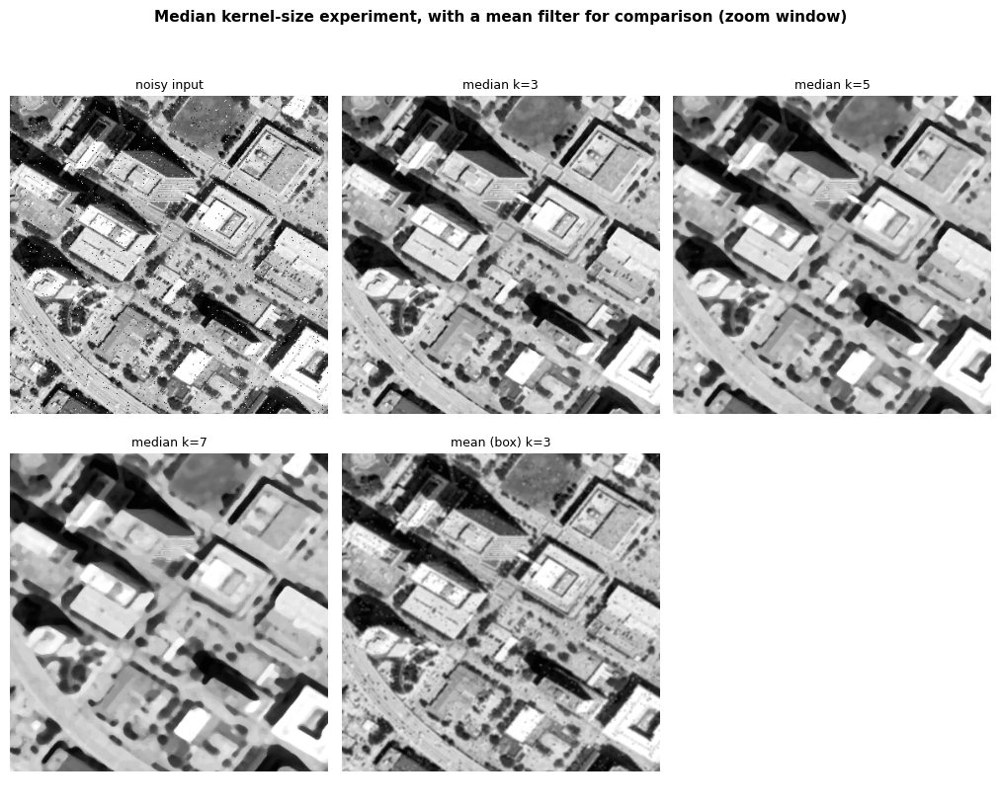

In [11]:
show([noisy, den_imgs["median k=3"]], ["Input: CLAHE + 2% synthetic salt-and-pepper noise", "Output: median filter k=3"],
     suptitle="Median filtering: before / after", size=5)
show(list(den_imgs.values()), list(den_imgs.keys()), cols=3, size=3.4,
     suptitle="Median kernel-size experiment, with a mean filter for comparison (zoom window)", crop=True)

**Parameter result.** **k = 3 worked best**: PSNR rises from 21.8 to 26.2 dB and edge correlation from 0.51 to 0.59.
Larger kernels remove the noise too, but they blur so much that they score *worse* than the noisy input (k = 5:
22.2 dB and 0.38; k = 7: 20.2 dB and 0.27). In the zoom window, cars, lot striping and thin ramps disappear at k = 7.
The 3 x 3 mean filter scores lower on both measures (23.8 dB and 0.36) because it smears the impulses into gray
blotches instead of removing them. This confirms that the median filter suits this kind of noise.

**Analysis.**

- *What changed:* the impulse noise is removed almost completely at k = 3.
- *Did it help:* yes for impulse noise. However, on the **real** image (which has no impulse noise), k = 3 changes the
  image by 26.5 dB PSNR and keeps only 0.61 edge correlation. It removes real detail such as cars and lot markings
  without removing any noise.
- *Unwanted effects:* loss of small, real structures, which gets worse quickly at larger kernel sizes.
- *Decision:* **modify**. We will use the median filter only when a scene actually has impulse noise or speckle, and
  **remove** it from the default chain for this clean NAIP scene. Smoothing before edge detection is handled better by
  a Gaussian blur (Section 3.5).

**Laplacian sharpening** computes $g = f - w\,\nabla^2 f$ on the CLAHE output. We tested weights from 0.03 to 0.6 and
measured the fraction of hard-clipped (0 or 255) pixels, which indicates overshoot and ringing, along with the mean
absolute Laplacian, which indicates fine-detail energy.

In [12]:
lap = cv2.Laplacian(clahe_img, cv2.CV_64F, ksize=3)
rows, sharp_imgs = [], {}
for w in [0.03, 0.05, 0.1, 0.2, 0.6]:
    out = np.clip(clahe_img.astype(np.float64) - w * lap, 0, 255).astype(np.uint8)
    sharp_imgs[w] = out
    rows.append({"weight": w, "% pixels clipped (0/255)": 100 * np.mean((out == 0) | (out == 255)),
                 "mean |Laplacian| (detail energy)": np.mean(np.abs(cv2.Laplacian(out, cv2.CV_64F, ksize=3)))})
sharpen_table = pd.DataFrame(rows)
print(f"unsharpened CLAHE: {100 * np.mean((clahe_img == 0) | (clahe_img == 255)):.1f}% clipped, "
      f"detail energy {np.mean(np.abs(lap)):.1f}")
sharp = sharp_imgs[0.05]
sharpen_table

unsharpened CLAHE: 2.3% clipped, detail energy 105.3


,weight,% pixels clipped (0/255),mean |Laplacian| (detail energy)
0,0.03,3.450,131.618
1,0.05,4.586,149.023
2,0.10,7.848,190.934
3,0.20,14.727,263.669
4,0.60,35.766,444.294


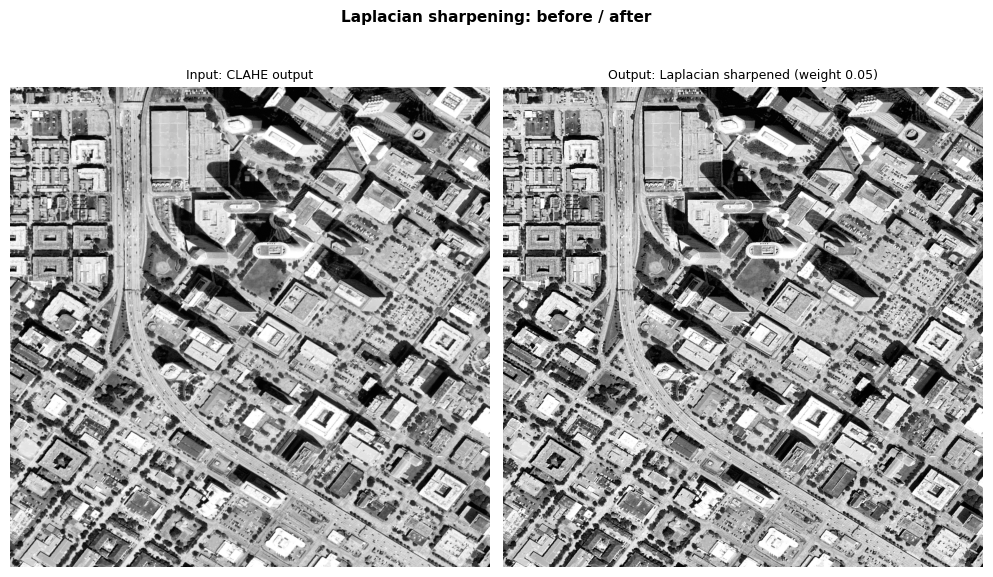

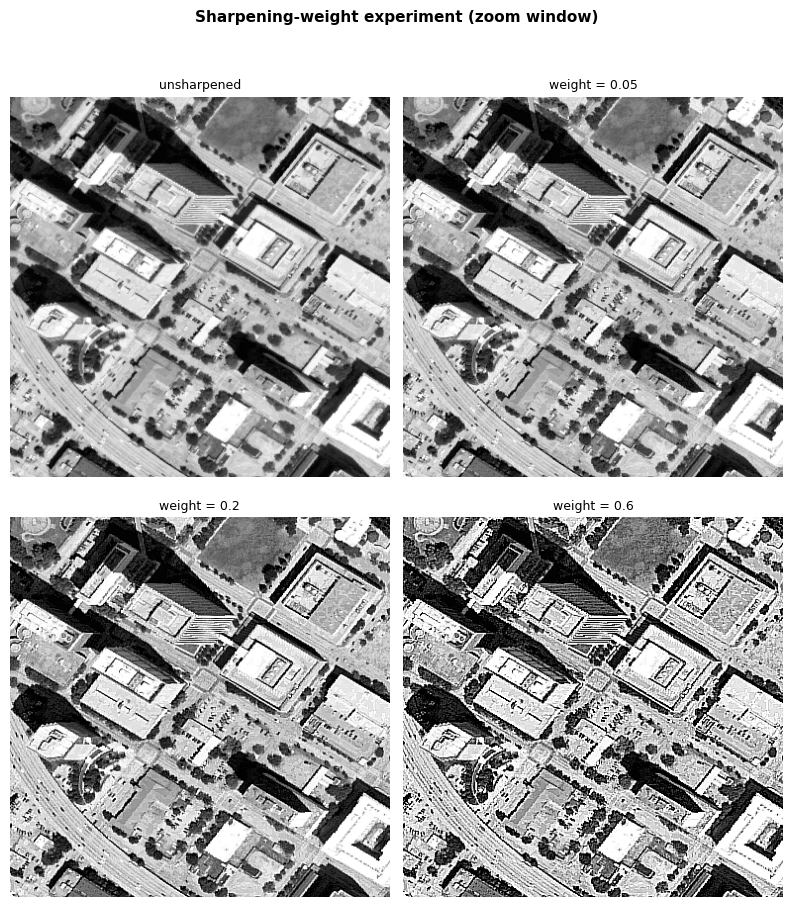

In [13]:
show([clahe_img, sharp], ["Input: CLAHE output", "Output: Laplacian sharpened (weight 0.05)"],
     suptitle="Laplacian sharpening: before / after", size=5)
show([clahe_img] + [sharp_imgs[w] for w in [0.05, 0.2, 0.6]],
     ["unsharpened"] + [f"weight = {w}" for w in [0.05, 0.2, 0.6]],
     cols=2, size=4, suptitle="Sharpening-weight experiment (zoom window)", crop=True)

**Parameter result.** Detail energy rises steadily with $w$, and so does clipping: 3.5% at 0.03, 4.6% at 0.05, 7.8% at
0.1, 14.7% at 0.2 and 35.8% at 0.6. With a 5% clipping budget, **$w = 0.05$ is the strongest setting we can use**.
It raises detail energy from 105 to 149 (+42%). At $w = 0.2$ and above, the zoom window shows bright and dark halos
around every roof edge and car, and pavement turns noisy.

**Analysis.**

- *What changed:* roof edges, curbs and ramp boundaries look crisper.
- *Did it help:* yes for visual interpretation. For edge detection the effect is mixed, because sharpening also
  amplifies texture and contributes to the overly dense Phase 1 Canny result (Section 3.5).
- *Unwanted effects:* halos and noise amplification at higher weights; even at 0.05, about 2.3 percentage points of
  extra pixels are clipped.
- *Decision:* **keep at w = 0.05** for the enhanced visual output, but always follow it with a Gaussian blur before
  edge and corner detection.

### 3.4 Frequency-Domain Filtering -- FFT Low-Pass / High-Pass

We take the 2-D FFT of the CLAHE output and choose the cut-off radius from the image's own radial power spectrum. We
use the smallest radius that contains 90% of the AC power, excluding the DC term (the image mean, which would
otherwise satisfy any threshold at r = 0). We then compare ideal (hard-cutoff) low-pass filters at r = 60 (our Phase 1
value), at that 90% radius, and at r = 250, plus a **Gaussian** low-pass $H = e^{-D^2/2D_0^2}$ at the same radius. Each
is scored by the AC power it keeps and the PSNR of its reconstruction against the input.

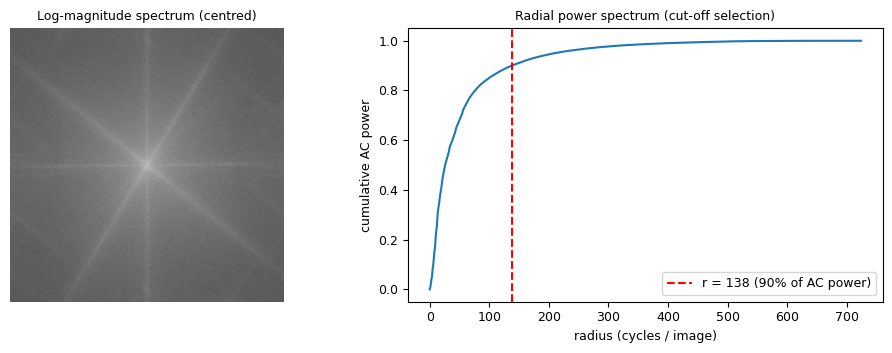

,low-pass filter,% AC power kept,PSNR vs input (dB)
0,ideal r=60,73.574,16.755
1,ideal r=138,89.905,20.945
2,ideal r=250,96.469,25.508
3,Gaussian D0=138,82.910,23.074


In [14]:
F = np.fft.fftshift(np.fft.fft2(clahe_img.astype(np.float64)))
h, w = clahe_img.shape
cy, cx = h // 2, w // 2
Y, X = np.ogrid[:h, :w]
D = np.sqrt((X - cx) ** 2 + (Y - cy) ** 2)

power = np.abs(F) ** 2
radial = np.bincount(D.astype(int).ravel(), weights=power.ravel())
radial[0] = 0.0                       # exclude DC (image mean), otherwise r=0 already holds most power
cum = np.cumsum(radial) / radial.sum()
r90 = int(np.searchsorted(cum, 0.90))

def inv(spec):
    return np.real(np.fft.ifft2(np.fft.ifftshift(spec)))

lp_imgs, rows = {}, []
for name, H in [("ideal r=60", (D <= 60).astype(float)),
                (f"ideal r={r90}", (D <= r90).astype(float)),
                ("ideal r=250", (D <= 250).astype(float)),
                (f"Gaussian D0={r90}", np.exp(-(D ** 2) / (2.0 * r90 ** 2)))]:
    out = np.clip(inv(F * H), 0, 255).astype(np.uint8)
    lp_imgs[name] = out
    ac = (power * H ** 2).copy(); ac[cy, cx] = 0
    rows.append({"low-pass filter": name, "% AC power kept": 100 * ac.sum() / (power.sum() - power[cy, cx]),
                 "PSNR vs input (dB)": psnr(clahe_img, out)})
fft_table = pd.DataFrame(rows)

hp = inv(F * (1 - np.exp(-(D ** 2) / (2.0 * r90 ** 2))))
hp_img = cv2.normalize(hp, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].imshow(np.log1p(np.abs(F)), cmap="gray"); axes[0].set_title("Log-magnitude spectrum (centred)"); axes[0].axis("off")
axes[1].plot(cum); axes[1].axvline(r90, color="r", ls="--", label=f"r = {r90} (90% of AC power)")
axes[1].set_xlabel("radius (cycles / image)"); axes[1].set_ylabel("cumulative AC power"); axes[1].legend()
axes[1].set_title("Radial power spectrum (cut-off selection)")
fig.tight_layout(); plt.show()
fft_table

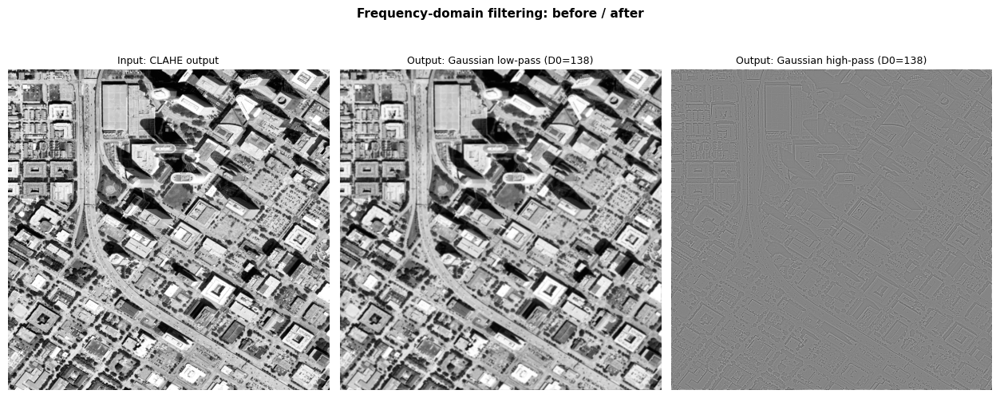

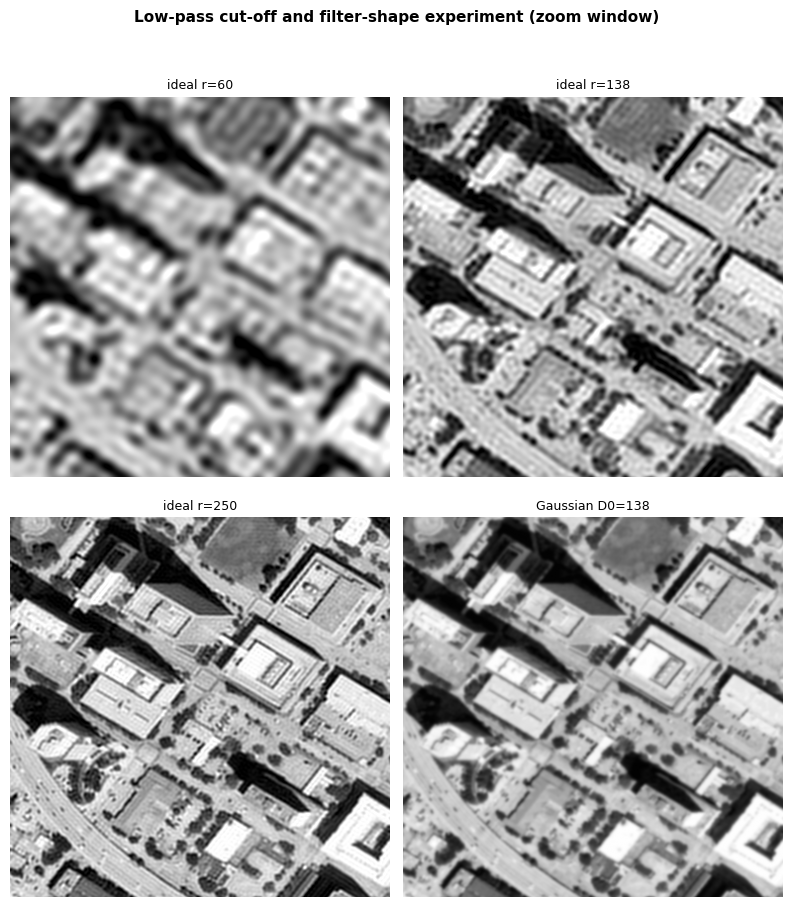

In [15]:
show([clahe_img, lp_imgs[f"Gaussian D0={r90}"], hp_img],
     ["Input: CLAHE output", f"Output: Gaussian low-pass (D0={r90})", f"Output: Gaussian high-pass (D0={r90})"],
     suptitle="Frequency-domain filtering: before / after", size=4.2)
show(list(lp_imgs.values()), list(lp_imgs.keys()), suptitle="Low-pass cut-off and filter-shape experiment (zoom window)",
     crop=True, cols=2, size=4)

**Parameter result.** The 90%-power radius is r = 138 cycles. The Phase 1 value of r = 60 keeps only 74% of the AC
power, gives 16.8 dB, and blurs the scene into blobs with clear ringing. The ideal filter at r = 138 keeps building
blocks and roads readable (20.9 dB), but its hard cut-off produces faint ripples parallel to strong edges (Gibbs
ringing). The **Gaussian filter at $D_0 = 138$ worked best**. It keeps *less* AC power than the ideal filter (83% vs.
90%) yet reconstructs the image *more* accurately (23.1 vs. 20.9 dB), because it has no ringing. The r = 250 filter
keeps almost everything (25.5 dB) and barely smooths, which defeats the purpose of a low-pass step.

**Analysis.**

- *What changed:* the low-pass output keeps coarse regions (building blocks, lawns, the highway corridor) and removes
  small detail (cars, lot striping, tree texture). The high-pass output keeps only the fine structure: street grid,
  roof edges and lane markings.
- *Did it help:* yes for our goal of separating coarse regions from fine detail. The low-pass image has much more
  uniform regions, which should be easier to segment.
- *Unwanted effects:* the ideal filter rings, and too small a cut-off merges neighboring land-cover classes. The
  high-pass result is noisy and best used as a structure map, not a display image.
- *Decision:* **modify**. Replace the ideal mask with a Gaussian one, and compute the cut-off on the enhanced image
  (which gives 138 instead of the 125 measured on the raw grayscale). The low-pass output becomes the input for region
  segmentation in Phase 3.

### 3.5 Edge & Corner Detection -- Canny and Harris

**Canny.** In Phase 1 we ran Canny on the sharpened image, with thresholds set by the median-gradient rule (low =
0.66 x median, high = 1.33 x median of the Sobel gradient magnitude). We compare four settings:

- A: the Phase 1 setting.
- B: the same rule without sharpening.
- C: Gaussian blur (5 x 5, $\sigma$ = 1.4) before Canny.
- D: Gaussian blur plus stricter thresholds (1.0 x / 2.0 x median).

Without ground-truth edges we use objective structure metrics: edge-pixel density, number of connected edge
segments, mean segment length (longer means more continuous outlines), and the share of tiny segments under 10 px,
which are mostly texture speckle rather than real boundaries.

In [16]:
def median_rule(img, lo=0.66, hi=1.33):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    m = float(np.median(np.hypot(gx, gy)))
    return lo * m, min(255.0, hi * m)

def edge_stats(name, img, lo, hi):
    e = cv2.Canny(img, int(lo), int(hi))
    n, _, stats, _ = cv2.connectedComponentsWithStats((e > 0).astype(np.uint8), connectivity=8)
    sizes = stats[1:, cv2.CC_STAT_AREA]
    return e, {"setting": name, "low": lo, "high": hi, "% edge pixels": 100 * np.mean(e > 0),
               "edge segments": n - 1, "mean segment length (px)": sizes.mean(),
               "% segments < 10 px (speckle)": 100 * np.mean(sizes < 10)}

smooth = cv2.GaussianBlur(sharp, (5, 5), 1.4)
settings = [("A: sharpened, median rule (Phase 1)", sharp, *median_rule(sharp)),
            ("B: CLAHE (no sharpening), median rule", clahe_img, *median_rule(clahe_img)),
            ("C: sharpened + Gaussian blur, median rule", smooth, *median_rule(smooth)),
            ("D: sharpened + Gaussian blur, 1.0x / 2.0x median", smooth, *median_rule(smooth, 1.0, 2.0))]
canny_imgs, rows = {}, []
for name, img, lo, hi in settings:
    e, r = edge_stats(name, img, lo, hi)
    canny_imgs[name] = e
    rows.append(r)
canny_table = pd.DataFrame(rows)
canny_table

,setting,low,high,% edge pixels,edge segments,mean segment length (px),% segments < 10 px (speckle)
0,"A: sharpened, median rule (Phase 1)",65.716,132.427,27.580,11999,24.101,69.156
1,"B: CLAHE (no sharpening), median rule",56.073,112.995,26.140,10582,25.902,65.451
2,"C: sharpened + Gaussian blur, median rule",44.899,90.479,18.630,5546,35.224,44.176
3,"D: sharpened + Gaussian blur, 1.0x / 2.0x median",68.029,136.059,16.104,3703,45.601,31.704


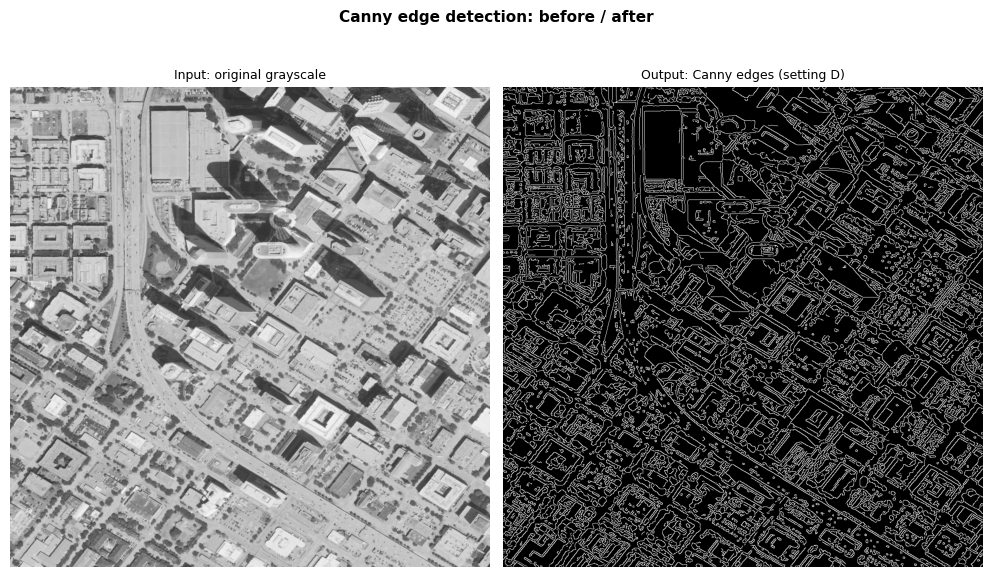

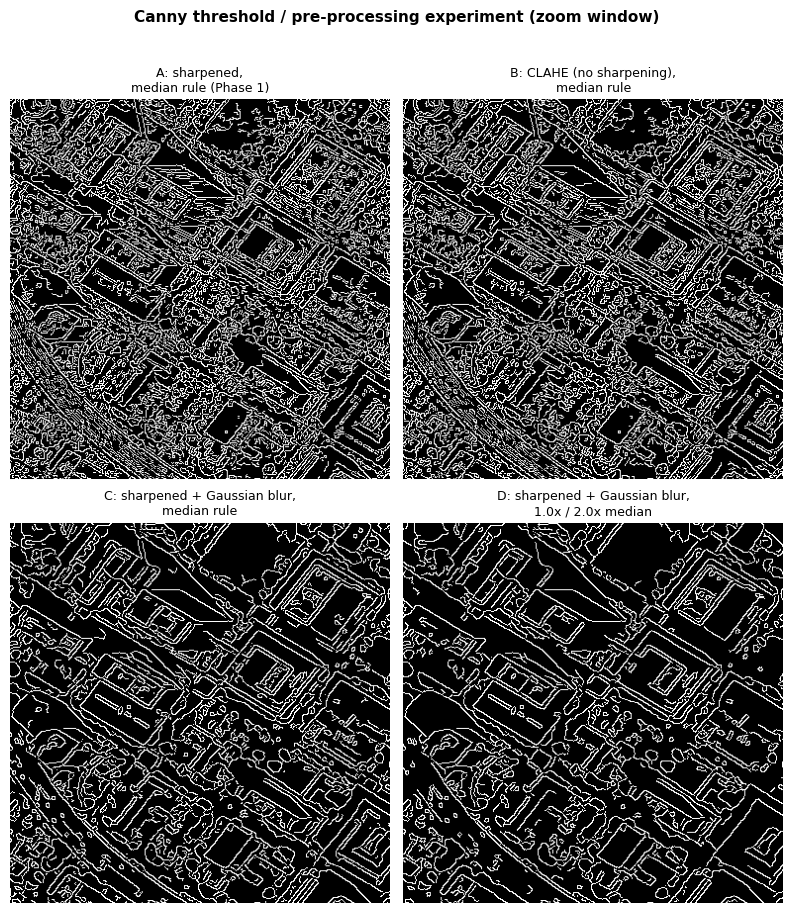

In [17]:
best_canny = canny_imgs["D: sharpened + Gaussian blur, 1.0x / 2.0x median"]
show([gray, best_canny], ["Input: original grayscale", "Output: Canny edges (setting D)"],
     suptitle="Canny edge detection: before / after", size=5)
show(list(canny_imgs.values()), [k.split(",")[0] + ",\n" + k.split(",", 1)[1].strip() for k in canny_imgs], cols=2,
     size=4, suptitle="Canny threshold / pre-processing experiment (zoom window)", crop=True)

**Parameter result.** The Phase 1 setting (A) marks 27.6% of all pixels as edges. 69% of its segments are shorter than
10 px, and the zoom window looks like dense texture rather than outlines. Removing sharpening (B) barely helps (26.1%).
Most of the clutter comes from fine texture, not the sharpening weight. Blurring first (C) cuts the density to 18.6%
and speckle to 44%. **Setting D worked best**: 16.1% edge pixels, 3,703 segments instead of 11,999, mean segment
length 45.6 px instead of 24.1 px, and only 32% speckle. Building footprints, the highway edges and the ramp curves now
form continuous lines.

**Analysis.**

- *What changed:* the edge map went from a texture map to an outline map.
- *Did it help:* yes. Long, connected building and road boundaries are what a later segmentation step needs.
- *Unwanted effects:* stricter thresholds drop some weak edges, such as low-contrast roof edges and lane lines inside
  shadows. Trees still produce small closed contours.
- *Decision:* **modify**. Use a Gaussian blur followed by Canny with 1.0 x / 2.0 x median thresholds.

**Harris corners.** We vary the response threshold (0.01, 0.05 and 0.10 of the maximum response), the sensitivity
$k$ (0.04 vs. 0.06), and the input (sharpened vs. sharpened + blurred). Because each corner covers several pixels, we
count "corner clusters" (connected groups of corner pixels) as an approximate keypoint count.

In [18]:
def harris_overlay(img, k, frac):
    R = cv2.cornerHarris(np.float32(img), blockSize=2, ksize=3, k=k)
    mask = R > frac * R.max()
    n_blobs = cv2.connectedComponents(cv2.dilate(mask.astype(np.uint8), None), connectivity=8)[0] - 1
    ov = color.copy()
    ov[cv2.dilate(mask.astype(np.uint8), None) == 1] = (0, 0, 255)
    return ov, {"input": "sharpened" if img is sharp else "sharpened + Gaussian blur", "k": k, "threshold (x max R)": frac,
                "corner pixels": int(mask.sum()), "corner clusters (~keypoints)": n_blobs}

harris_imgs, rows = {}, []
for img, k, frac in [(sharp, 0.04, 0.01), (sharp, 0.04, 0.05), (sharp, 0.04, 0.10), (sharp, 0.06, 0.05), (smooth, 0.04, 0.05)]:
    ov, r = harris_overlay(img, k, frac)
    harris_imgs[f"{r['input']}\nk={k}, thr={frac} x max"] = ov
    rows.append(r)
harris_table = pd.DataFrame(rows)
harris_table

,input,k,threshold (x max R),corner pixels,corner clusters (~keypoints)
0,sharpened,0.04,0.01,61967,4075
1,sharpened,0.04,0.05,15884,3466
2,sharpened,0.04,0.10,6143,2215
3,sharpened,0.06,0.05,13250,3281
4,sharpened + Gaussian blur,0.04,0.05,9151,1959


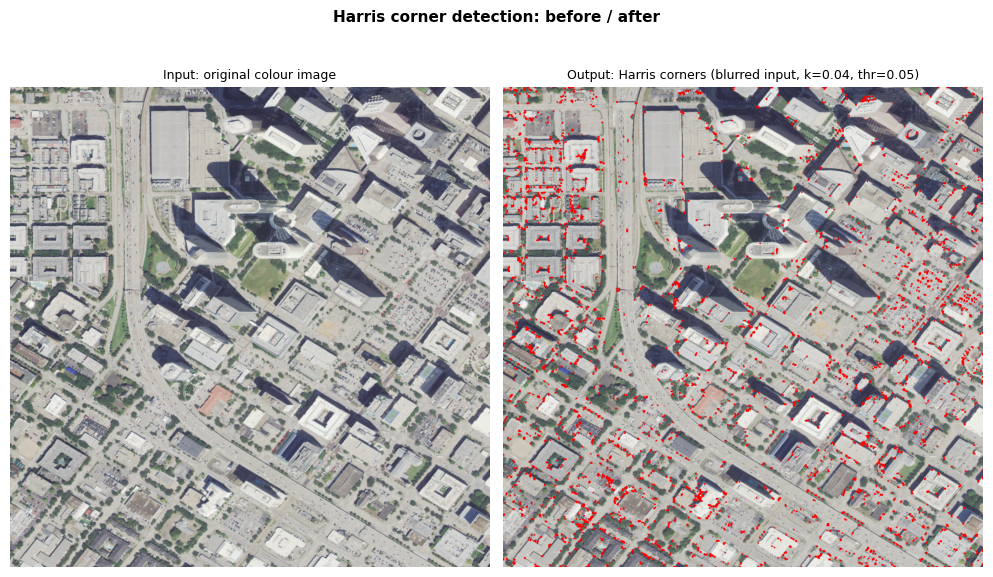

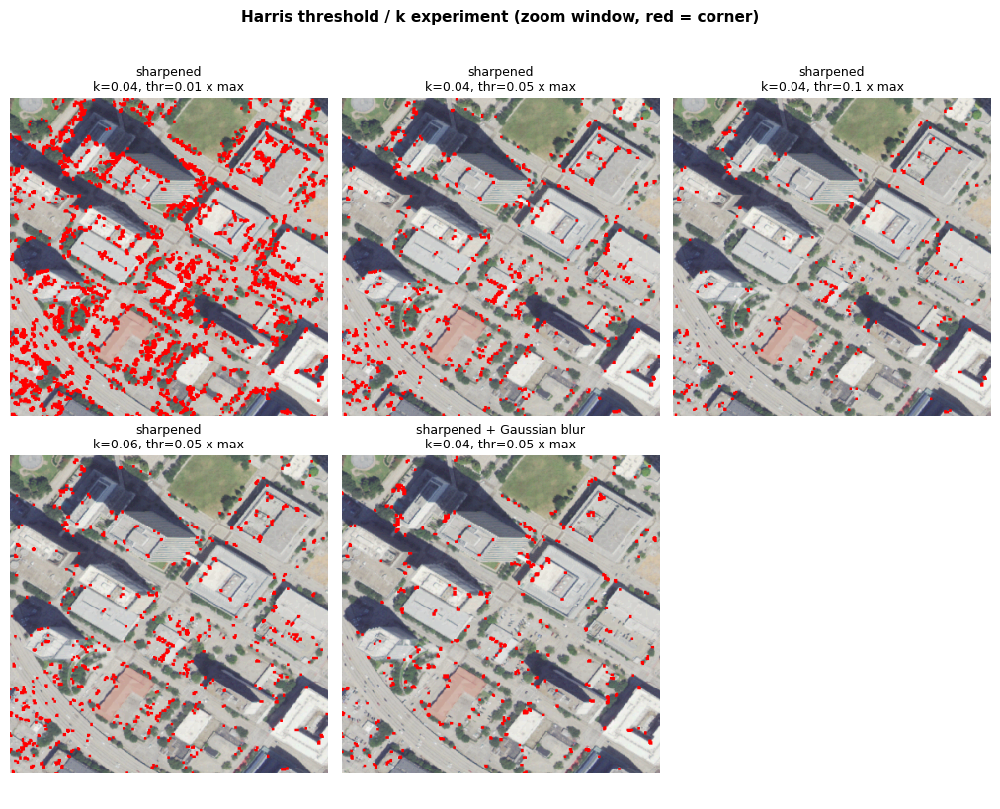

In [19]:
show([color, harris_imgs["sharpened + Gaussian blur\nk=0.04, thr=0.05 x max"]],
     ["Input: original colour image", "Output: Harris corners (blurred input, k=0.04, thr=0.05)"],
     suptitle="Harris corner detection: before / after", size=5)
show(list(harris_imgs.values()), list(harris_imgs.keys()), cols=3, size=3.4,
     suptitle="Harris threshold / k experiment (zoom window, red = corner)", crop=True)

**Parameter result.** The Phase 1 threshold (0.01 x max) flags 62k pixels in 4,075 clusters. The zoom window is covered
in red, including tree canopy and pavement texture. Raising the threshold to 0.05 cuts this to 15.9k pixels and 3,466
clusters, and 0.10 cuts it to 2,215 clusters but starts missing real building corners. Changing $k$ from 0.04 to 0.06
has a smaller effect (3,466 to 3,281 clusters). **Blurred input with threshold 0.05 worked best**: 1,959 clusters,
concentrated on building corners, roof structures and road junctions, with far fewer hits in tree canopy.

**Analysis.**

- *What changed:* corners are now sparse, interpretable keypoints instead of a texture response.
- *Did it help:* yes. The remaining corners match real structure, which is what we wanted as a proxy for structural
  complexity.
- *Unwanted effects:* tree crowns and cars still produce some corners, and a few corners on low-contrast roofs are
  lost.
- *Decision:* **modify**. Run Harris on the blurred image with threshold 0.05 x max and $k$ = 0.04. Add non-maximum
  suppression in Phase 3 to get exactly one point per corner.

## 4. Preliminary Evaluation

We do not have pixel-level ground truth for this scene yet, so each stage is scored with a metric that matches its
purpose: reaching a target mean intensity, balanced contrast gain, PSNR against a clean reference, clipped-pixel
fraction, and edge continuity and speckle. The table compares the Phase 1 or baseline setting with the current
choice. The figure shows the intermediate result of each stage on the full frame.

In [20]:
g = gamma_table.set_index("gamma")
c = clahe_table.set_index("method")
m = median_table.set_index("filter")
s = sharpen_table.set_index("weight")
f = fft_table.set_index("low-pass filter")
e = canny_table.set_index("setting")
hr = harris_table
summary = pd.DataFrame([
    ["Gamma", "shadow-quartile mean (target 110)", f"{g.iloc[0]['shadow mean']:.1f} (no gamma)", f"{g.loc[gamma_auto, 'shadow mean']:.1f} (gamma={gamma_auto:.3f})"],
    ["CLAHE", "dark/bright gain balance (1.0 = even)", f"{c.loc['global HE', 'balance (dark/bright)']:.2f} (global HE)", f"{c.loc['CLAHE clip=2.5, tile=8', 'balance (dark/bright)']:.2f} (clip 2.5, tile 8)"],
    ["Median", "PSNR vs clean reference (dB)", f"{m.loc['noisy input', 'PSNR vs clean (dB)']:.1f} (noisy)", f"{m.loc['median k=3', 'PSNR vs clean (dB)']:.1f} (k=3)"],
    ["Sharpening", "% clipped pixels (budget 5%)", f"{s.loc[0.6, '% pixels clipped (0/255)']:.1f} (w=0.6)", f"{s.loc[0.05, '% pixels clipped (0/255)']:.1f} (w=0.05)"],
    ["FFT low-pass", "PSNR vs input (dB)", f"{f.loc['ideal r=60', 'PSNR vs input (dB)']:.1f} (ideal r=60)", f"{f.loc[f'Gaussian D0={r90}', 'PSNR vs input (dB)']:.1f} (Gaussian D0={r90})"],
    ["Canny", "% edge pixels / % speckle segments",
     f"{e.iloc[0]['% edge pixels']:.1f} / {e.iloc[0]['% segments < 10 px (speckle)']:.0f} (setting A)",
     f"{e.iloc[3]['% edge pixels']:.1f} / {e.iloc[3]['% segments < 10 px (speckle)']:.0f} (setting D)"],
    ["Harris", "corner clusters", f"{hr.iloc[0]['corner clusters (~keypoints)']} (thr 0.01)", f"{hr.iloc[4]['corner clusters (~keypoints)']} (blurred, thr 0.05)"],
], columns=["stage", "metric", "Phase 1 / baseline", "current choice"])
summary

,stage,metric,Phase 1 / baseline,current choice
0,Gamma,shadow-quartile mean (target 110),89.5 (no gamma),109.1 (gamma=1.245)
1,CLAHE,dark/bright gain balance (1.0 = even),0.66 (global HE),"0.87 (clip 2.5, tile 8)"
2,Median,PSNR vs clean reference (dB),21.8 (noisy),26.2 (k=3)
3,Sharpening,% clipped pixels (budget 5%),35.8 (w=0.6),4.6 (w=0.05)
4,FFT low-pass,PSNR vs input (dB),16.8 (ideal r=60),23.1 (Gaussian D0=138)
5,Canny,% edge pixels / % speckle segments,27.6 / 69 (setting A),16.1 / 32 (setting D)
6,Harris,corner clusters,4075 (thr 0.01),"1959 (blurred, thr 0.05)"


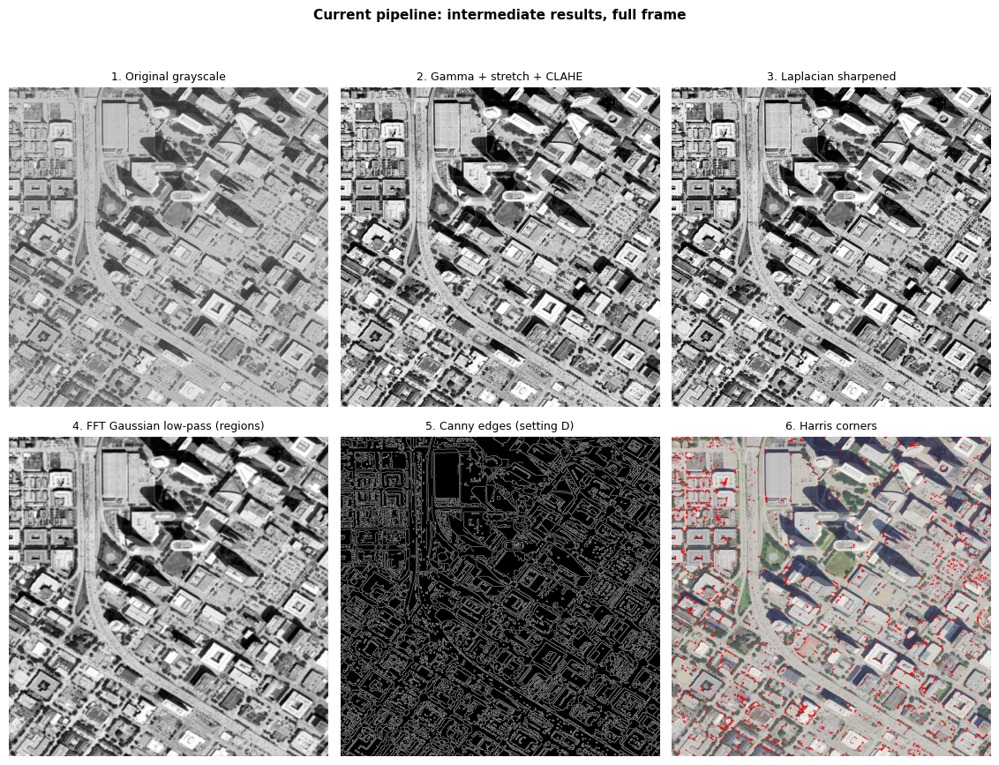

In [21]:
show([gray, clahe_img, sharp, lp_imgs[f"Gaussian D0={r90}"], best_canny, harris_imgs["sharpened + Gaussian blur\nk=0.04, thr=0.05 x max"]],
     ["1. Original grayscale", "2. Gamma + stretch + CLAHE", "3. Laplacian sharpened", "4. FFT Gaussian low-pass (regions)",
      "5. Canny edges (setting D)", "6. Harris corners"],
     cols=3, size=3.8, suptitle="Current pipeline: intermediate results, full frame")

**Summary.** Every stage now has a measurable reason for its parameters:

- Gamma reaches its shadow target within 1%.
- CLAHE is measurably more balanced than global HE (0.87 vs. 0.66).
- The median filter recovers 4.4 dB on impulse noise but is not needed on this clean image.
- Sharpening stays within the 5% clipping budget.
- The Gaussian low-pass beats the ideal filter (23.1 vs. 20.9 dB) at the same radius.

The largest improvement over Phase 1 is in edge detection: edge density fell from 27.6% to 16.1%, and the share of
speckle segments fell from 69% to 32%. The main limitation is that these are *proxy* metrics. In Phase 3 we plan to
score edges against reference building and road outlines (see Next Steps).

## 5. Updated Pipeline

Current planned sequence. Changes from the Phase 1 proposal are in **bold**.

1. **Load** the NAIP 1 m RGB crop and convert it to grayscale.
2. **Gamma correction** with $\gamma$ solved from the shadow-quartile mean (1.245 for this scene; Phase 1 used a fixed 1.4).
3. **Linear contrast stretch**, 2nd/98th percentile clip.
4. **CLAHE**, clip 2.5 and 8 x 8 tiles (clip 1.5 to 2.0 to be evaluated).
5. **Median filter, k = 3, only when impulse noise or speckle is present** (Phase 1 used k = 5 always; removed from the default chain for this clean scene).
6. **Laplacian sharpening**, weight 0.05 (largest weight within the 5% clipping budget), for the enhanced visual output.
7. **Gaussian blur (5 x 5, $\sigma$ = 1.4) before feature extraction** (new step).
8. **Canny edges with 1.0 x / 2.0 x median-gradient thresholds** (Phase 1 used 0.66 x / 1.33 x on the unblurred image).
9. **Harris corners on the blurred image, threshold 0.05 x max response, k = 0.04** (Phase 1 used 0.01 x max).

Frequency-domain branch, taken from the CLAHE output after step 4:

- **Gaussian low-pass**, $D_0$ = 90%-AC-power radius (138 here; Phase 1 used an ideal r = 60). This gives the region
  map for land-cover segmentation.
- **Gaussian high-pass** at the same $D_0$. This gives the fine-structure map (street grid, roof edges).

```
RGB -> gray -> gamma -> stretch -> CLAHE
                                     |
        +----------------------------+--------------------------+
        |                                                       |
  sharpen (display)                              FFT Gaussian low-pass (regions)
        |                                        FFT Gaussian high-pass (structure)
  Gaussian blur
        |
  Canny edges + Harris corners
```

## 6. Next Steps

**What still needs to be completed**

- A land-cover separation step that combines the outputs: thresholding or region growing on the low-pass image, plus
  simple color indices from the RGB bands, such as excess green ($2G - R - B$) for vegetation. This would produce
  approximate road, building, vegetation and water maps; at the moment the pipeline only works in grayscale.
- An objective accuracy check against reference data. We plan to compare Canny edges with OpenStreetMap building and
  road outlines for the same bounding box, reporting edge precision and recall, or to hand-label a small patch.
- Re-tune the remaining open parameters downstream: CLAHE clip 1.5 vs. 2.5, and whether blurring the CLAHE output
  directly (no sharpening) gives equally clean Canny edges.
- Non-maximum suppression for Harris, so each corner is a single keypoint.
- (Optional) Deep-learning extension. A COCO-pretrained YOLOv8n returned no detections on this 1 m scene during
  Phase 1 testing, because cars are only about 4 to 5 px wide. We plan to try an aerial-trained model (YOLOv8-OBB
  trained on DOTA) on tiled, upsampled patches.

**Problems and challenges encountered**

- The real NAIP crop has almost no impulse noise, so the median filter could only be tested with synthetic noise.
  It turned out to be unnecessary for this scene.
- Without ground truth, we had to design proxy metrics for each stage.
- The Phase 1 edge detector was far too dense (27.6% of pixels). We traced this to texture amplification by the
  enhancement stages and fixed it with blurring and stricter thresholds.
- Gamma brightens shadows but compresses highlights, so it must be paired with stretching or CLAHE.
- During development we fixed an inverted gamma formula and an FFT cut-off search that always returned r = 0 because
  the DC term was included.

**Planned improvements before Phase 3**

- Test the pipeline on a second NAIP scene (e.g., a residential or bayou area) to check that the self-tuning
  parameters generalize.
- Try an FFT band-pass filter, as mentioned in the proposal, to isolate the street-grid frequency band.
- Combine the edge, corner and region outputs into one land-cover overlay for the final report.